In [ ]:
#================================================== LIBRERÍAS ===============================================

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import joblib

import pandas as pd
import os

import shutil
from google.colab import drive

import numpy as np
import shap

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt


In [ ]:
#================================================== LECTURA DE INPUTS ===============================================

print("Mounting Google Drive...")
drive.mount('/content/drive', force_remount=True)
print("Google Drive mounted.")

drive_path = '/content/drive/MyDrive/Master/TFM/Modelos TFM/'
file_path = os.path.join(drive_path, 'dataset_modelo.csv') # Correctly define file_path

try:
    dataset_modelo = pd.read_csv(file_path)
    print(f"Dataset '{file_path}' cargado exitosamente. Filas: {len(dataset_modelo)}")
    display(dataset_modelo.head())
except FileNotFoundError:
    print(f"Error: El archivo '{file_path}' no fue encontrado. Por favor, verifica la ruta y asegúrate de que el archivo existe en tu Google Drive.")
except Exception as e:
    print(f"Ocurrió un error al cargar el dataset: {e}")

Mounting Google Drive...
Mounted at /content/drive
Google Drive mounted.
Dataset '/content/drive/MyDrive/Master/TFM/Modelos TFM/dataset_modelo.csv' cargado exitosamente. Filas: 3297


,CheckIn,dias_vista,habitaciones_vendidas,ocupacion_actual,adr_actual,lead_time,ocupacion_final,adr_final,Canal_Booking,Canal_Expedia,...,Es_Verano,Es_Invierno,Es_Puente,FinMes,InicioMes,Mes_sin,Mes_cos,DiaSemana_sin,DiaSemana_cos,nivel_ocupacion
0,2023-01-01,7,23,30.666667,108.913043,70.608696,33.333333,109.040000,1,0,...,0,1,0,0,1,0.5,0.866025,-0.781831,0.62349,Baja
1,2023-01-01,14,23,30.666667,108.913043,70.608696,33.333333,109.040000,1,0,...,0,1,0,0,1,0.5,0.866025,-0.781831,0.62349,Baja
2,2023-01-01,30,22,29.333333,109.727273,73.090909,33.333333,109.040000,1,0,...,0,1,0,0,1,0.5,0.866025,-0.781831,0.62349,Baja
3,2023-01-02,7,14,18.666667,108.857143,81.571429,18.666667,108.857143,1,0,...,0,1,0,0,1,0.5,0.866025,0.000000,1.00000,Baja
4,2023-01-02,14,14,18.666667,108.857143,81.571429,18.666667,108.857143,1,0,...,0,1,0,0,1,0.5,0.866025,0.000000,1.00000,Baja


In [ ]:
#================================================== VARIABLES DEL MODELO ============================================================

# 1. Calculamos el pickup real histórico
dataset_modelo["pickup"] = dataset_modelo["ocupacion_final"] - dataset_modelo["ocupacion_actual"]

# 2. Definimos el objetivo
objetivo = "pickup"

# 3. Definimos la lista de exclusión
excluir = [
    "CheckIn",                  # Identificador temporal
    "ocupacion_final",          # EVITAR DATA LEAKAGE: La excluimos
    "adr_final",                # Información del futuro
    "nivel_ocupacion",          # Derivada del objetivo
    "Año",                      # No generaliza a años futuros
    "habitaciones_vendidas",    # Redundante con ocupacion_actual
    "Mes",                      # Redundante con Mes_sin y Mes_cos
    "DiaSemana",                # Redundante con DiaSemana_sin y DiaSemana_cos
    "Es_Puente",                # Importancia nula
    "pickup"                    # El objetivo no debe estar en las features
]

variables = [c for c in dataset_modelo.columns if c not in excluir]

X = dataset_modelo[variables]
y = dataset_modelo[objetivo]

print(f"Variables predictoras: {len(variables)}")
display(X.head())

Variables predictoras: 36


,dias_vista,ocupacion_actual,adr_actual,lead_time,Canal_Booking,Canal_Expedia,Canal_Otros,Canal_Teléfono,Canal_Walk-in,Canal_Web,...,FinSemana,Festivo,Es_Verano,Es_Invierno,FinMes,InicioMes,Mes_sin,Mes_cos,DiaSemana_sin,DiaSemana_cos
0,7,30.666667,108.913043,70.608696,1,0,0,0,0,0,...,1,0,0,1,0,1,0.5,0.866025,-0.781831,0.62349
1,14,30.666667,108.913043,70.608696,1,0,0,0,0,0,...,1,0,0,1,0,1,0.5,0.866025,-0.781831,0.62349
2,30,29.333333,109.727273,73.090909,1,0,0,0,0,0,...,1,0,0,1,0,1,0.5,0.866025,-0.781831,0.62349
3,7,18.666667,108.857143,81.571429,1,0,0,0,0,0,...,0,0,0,1,0,1,0.5,0.866025,0.000000,1.00000
4,14,18.666667,108.857143,81.571429,1,0,0,0,0,0,...,0,0,0,1,0,1,0.5,0.866025,0.000000,1.00000


In [ ]:
print(dataset_modelo.columns.tolist())
print(dataset_modelo.head(3).to_dict(orient='records'))

['CheckIn', 'dias_vista', 'habitaciones_vendidas', 'ocupacion_actual', 'adr_actual', 'lead_time', 'ocupacion_final', 'adr_final', 'Canal_Booking', 'Canal_Expedia', 'Canal_Otros', 'Canal_Teléfono', 'Canal_Walk-in', 'Canal_Web', 'Tipo_Individual', 'Tipo_Otros', 'Tipo_Suite', 'Pais_EEUU', 'Pais_España', 'Pais_Francia', 'Pais_Italia', 'Pais_Otros', 'Pais_Portugal', 'Pais_Reino Unido', 'pickup_7', 'pickup_14', 'ocupacion_anio_anterior', 'adr_anio_anterior', 'Mes', 'Semana', 'DiaMes', 'DiaSemana', 'FinSemana', 'Año', 'Festivo', 'Es_Verano', 'Es_Invierno', 'Es_Puente', 'FinMes', 'InicioMes', 'Mes_sin', 'Mes_cos', 'DiaSemana_sin', 'DiaSemana_cos', 'nivel_ocupacion', 'pickup']
[{'CheckIn': '2023-01-01', 'dias_vista': 7, 'habitaciones_vendidas': 23, 'ocupacion_actual': 30.666666666666664, 'adr_actual': 108.91304347826087, 'lead_time': 70.6086956521739, 'ocupacion_final': 33.33333333333333, 'adr_final': 109.04, 'Canal_Booking': 1, 'Canal_Expedia': 0, 'Canal_Otros': 0, 'Canal_Teléfono': 0, 'Canal_

In [ ]:
X

,dias_vista,ocupacion_actual,adr_actual,lead_time,Canal_Booking,Canal_Expedia,Canal_Otros,Canal_Teléfono,Canal_Walk-in,Canal_Web,...,FinSemana,Festivo,Es_Verano,Es_Invierno,FinMes,InicioMes,Mes_sin,Mes_cos,DiaSemana_sin,DiaSemana_cos
0,7,30.666667,108.913043,70.608696,1,0,0,0,0,0,...,1,0,0,1,0,1,5.000000e-01,0.866025,-0.781831,0.623490
1,14,30.666667,108.913043,70.608696,1,0,0,0,0,0,...,1,0,0,1,0,1,5.000000e-01,0.866025,-0.781831,0.623490
2,30,29.333333,109.727273,73.090909,1,0,0,0,0,0,...,1,0,0,1,0,1,5.000000e-01,0.866025,-0.781831,0.623490
3,7,18.666667,108.857143,81.571429,1,0,0,0,0,0,...,0,0,0,1,0,1,5.000000e-01,0.866025,0.000000,1.000000
4,14,18.666667,108.857143,81.571429,1,0,0,0,0,0,...,0,0,0,1,0,1,5.000000e-01,0.866025,0.000000,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3292,14,13.333333,133.800000,77.700000,1,0,0,0,0,0,...,0,0,0,1,1,0,-2.449294e-16,1.000000,0.781831,0.623490
3293,30,13.333333,133.800000,77.700000,1,0,0,0,0,0,...,0,0,0,1,1,0,-2.449294e-16,1.000000,0.781831,0.623490
3294,7,1.333333,187.000000,64.000000,0,0,0,0,0,1,...,0,0,0,1,1,0,-2.449294e-16,1.000000,0.974928,-0.222521
3295,14,1.333333,187.000000,64.000000,0,0,0,0,0,1,...,0,0,0,1,1,0,-2.449294e-16,1.000000,0.974928,-0.222521


In [ ]:
#================================================== TRAIN / TEST#======================================#

train=dataset_modelo["Año"]<2025
test=dataset_modelo["Año"]==2025

X_train=X.loc[train]
X_test=X.loc[test]
y_train=y.loc[train]
y_test=y.loc[test]

print(f"Train: {len(X_train):,}")
print(f"Test : {len(X_test):,}")

Train: 2,193
Test : 1,104


In [ ]:
#================================================== VALIDACIÓN#================================================#
print(X_train.shape)
print(X_test.shape)

assert X_train.isnull().sum().sum()==0
assert X_test.isnull().sum().sum()==0

print("Datos preparados correctamente.")

(2193, 36)
(1104, 36)
Datos preparados correctamente.


In [ ]:
#================================================== ENTRENAMIENTO#==========================================#

modelo=XGBRegressor(objective="reg:squarederror",
                    n_estimators=300,
                    learning_rate=0.05,
                    max_depth=5,
                    subsample=0.8,
                    colsample_bytree=0.8,
                    random_state=42)

modelo.fit(X_train,y_train)
print("Modelo entrenado correctamente.")

Modelo entrenado correctamente.


In [ ]:
#================================================== EXPORTAR MODELO ============================================================

drive_path="/content/drive/MyDrive/Master/TFM/Modelos TFM/"
os.makedirs(drive_path,exist_ok=True)

modelo_path=os.path.join(drive_path,"modelo_ocupacion.pkl")
variables_path=os.path.join(drive_path,"variables_modelo.pkl")

joblib.dump(modelo,modelo_path)
joblib.dump(variables,variables_path)

print("Archivos guardados correctamente:")
print(f"• Modelo   : {modelo_path}")
print(f"• Variables: {variables_path}")

Archivos guardados correctamente:
• Modelo   : /content/drive/MyDrive/Master/TFM/Modelos TFM/modelo_ocupacion.pkl
• Variables: /content/drive/MyDrive/Master/TFM/Modelos TFM/variables_modelo.pkl


In [ ]:
#================================================== PREDICCIONES ============================================================

# El modelo predice el pickup
pred_pickup_train = modelo.predict(X_train)
pred_pickup_test = modelo.predict(X_test)

# Evitamos que el modelo reste ocupación (pickup negativo)
pred_pickup_train = np.maximum(0, pred_pickup_train)
pred_pickup_test = np.maximum(0, pred_pickup_test)

# Reconstruimos la predicción final (Ocupación Actual + Pickup Predicho)
pred_train_final = X_train["ocupacion_actual"] + pred_pickup_train
pred_test_final = X_test["ocupacion_actual"] + pred_pickup_test

# Reconstruimos el valor real para poder evaluar el error en las métricas
y_test_final = X_test["ocupacion_actual"] + y_test

print(f"Predicciones Train: {len(pred_train_final):,}")
print(f"Predicciones Test : {len(pred_test_final):,}")

Predicciones Train: 2,193
Predicciones Test : 1,104


In [ ]:
#================================================== MÉTRICAS ============================================================

# Calculamos el error sobre la ocupación final reconstruida, no solo sobre el pickup
mae = mean_absolute_error(y_test_final, pred_test_final)
mape = np.mean(np.abs((y_test_final - pred_test_final) / y_test_final.replace(0, np.nan))) * 100

rmse = np.sqrt(mean_squared_error(y_test_final, pred_test_final))

r2 = r2_score(y_test_final, pred_test_final)

metricas = pd.DataFrame({"Métrica":["MAE","RMSE","MAPE","R²"], "Valor":[mae,rmse,mape,r2]})

display(metricas)

,Métrica,Valor
0,MAE,1.411659
1,RMSE,1.940547
2,MAPE,8.558318
3,R²,0.832746


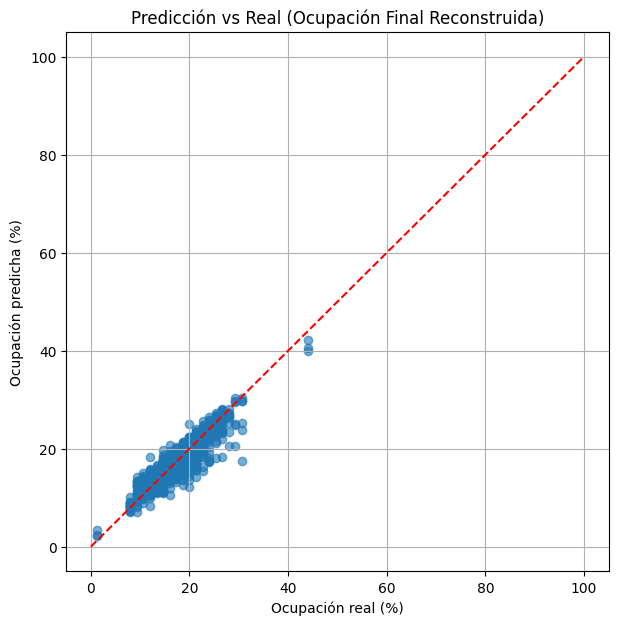

In [ ]:
#================================================== PREDICCIÓN VS REAL ===================================================

plt.figure(figsize=(7,7))
plt.scatter(y_test_final, pred_test_final, alpha=0.6)
plt.plot([0,100],[0,100],"r--")
plt.xlabel("Ocupación real (%)")
plt.ylabel("Ocupación predicha (%)")
plt.title("Predicción vs Real (Ocupación Final Reconstruida)")
plt.grid(True)
plt.show()

In [ ]:
#================================================== RESIDUALES ============================================================

errores = pred_test - y_test

plt.figure(figsize=(8,5))
plt.scatter(pred_test,errores,alpha=0.6)
plt.axhline(0,color="red",linestyle="--")
plt.xlabel("Predicción")
plt.ylabel("Residual")
plt.title("Análisis de residuales")
plt.grid(True)
plt.show()

NameError: name 'pred_test' is not defined

,Variable,Importancia
28,Es_Verano,0.542703
0,dias_vista,0.108347
29,Es_Invierno,0.065463
33,Mes_cos,0.030461
5,Canal_Expedia,0.013375
32,Mes_sin,0.013358
15,Pais_Francia,0.011967
3,lead_time,0.011947
22,ocupacion_anio_anterior,0.011594
7,Canal_Teléfono,0.010821


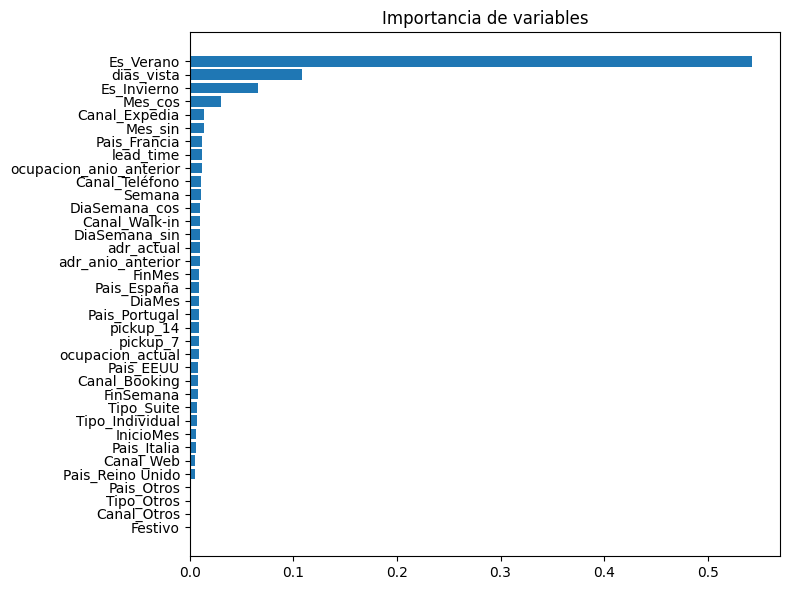

In [ ]:
#================================================== IMPORTANCIA DE VARIABLES ===================================================

importancias=pd.DataFrame({"Variable":variables,
                           "Importancia":modelo.feature_importances_}).sort_values("Importancia",ascending=False)

display(importancias)

plt.figure(figsize=(8,6))
plt.barh(importancias["Variable"],importancias["Importancia"])
plt.gca().invert_yaxis()
plt.title("Importancia de variables")
plt.tight_layout()
plt.show()

In [ ]:
#================================================== SHAP ============================================================

explainer=shap.TreeExplainer(modelo)
shap_values=explainer.shap_values(X_test)

shap.summary_plot(shap_values,X_test)

In [ ]:
#================================================== EXPORTAR RESULTADOS ============================================================

metricas.to_csv("metricas_modelo.csv",index=False)
importancias.to_csv("importancia_variables.csv",index=False)

predicciones=X_test.copy()
predicciones["Real"]=y_test.values
predicciones["Prediccion"]=pred_test
predicciones["Error"]=pred_test-y_test.values

predicciones.to_csv("predicciones.csv",index=False)

print("Resultados exportados correctamente.")

NameError: name 'pred_test' is not defined

In [ ]:
#================================================== RESUMEN DEL MODELO ============================================================

print("="*60)
print("RESUMEN DEL MODELO")
print("="*60)

if 'metricas' not in globals():
    mae = mean_absolute_error(y_test, pred_test)
    rmse = np.sqrt(mean_squared_error(y_test, pred_test))
    mape = np.mean(np.abs((y_test - pred_test) / y_test.replace(0, np.nan))) * 100
    r2 = r2_score(y_test, pred_test)
    metricas = pd.DataFrame({ "Métrica":["MAE","RMSE","MAPE","R²"], "Valor":[mae,rmse,mape,r2]})
    print("Nota: Las métricas fueron recalculadas para el resumen.")
else:
    mae = metricas[metricas["Métrica"] == "MAE"]["Valor"].iloc[0]
    rmse = metricas[metricas["Métrica"] == "RMSE"]["Valor"].iloc[0]
    mape = metricas[metricas["Métrica"] == "MAPE"]["Valor"].iloc[0]
    r2 = metricas[metricas["Métrica"] == "R²"]["Valor"].iloc[0]

print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAPE : {mape:.2f}%\n")
print(f"R²   : {r2:.4f}")

print("\nTop 10 variables:")
display(importancias.head(10))

In [ ]:
importancias=pd.DataFrame({
    "Variable":X_train.columns,
    "Importancia":modelo.feature_importances_
}).sort_values("Importancia",ascending=False)

display(importancias)

,Variable,Importancia
28,Es_Verano,0.542703
0,dias_vista,0.108347
29,Es_Invierno,0.065463
33,Mes_cos,0.030461
5,Canal_Expedia,0.013375
32,Mes_sin,0.013358
15,Pais_Francia,0.011967
3,lead_time,0.011947
22,ocupacion_anio_anterior,0.011594
7,Canal_Teléfono,0.010821


In [ ]:
dataset_modelo.columns.tolist()